# Volume Signal Sanity Check

**Question:** Does volume-correlation between two stocks carry information that is *different* from their return-correlation? If yes, we should build Trial 7 with multiple correlation streams (return + volume + volatility). If no, volume adds nothing useful and we skip ahead.

**Method:**
1. Pick 6 representative pairs (same sector, cross-sector, sector-specific).
2. For each pair, compute rolling correlations of three signals: returns, log-volume, and intraday volatility (high-low range).
3. Plot the three "correlation time series" side by side.
4. Quantify: cross-correlation between the three signals per pair. If near 1.0, they're redundant. If 0.4-0.8, they carry independent information.

Runs in under a minute on CPU.

In [1]:
# Cell 1 - Imports and Configuration
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

_cwd        = os.getcwd()
PROJECT_DIR = os.path.abspath(os.path.join(_cwd, '..')) \
              if os.path.basename(_cwd) == 'notebooks' else _cwd
RAW_DIR     = os.path.join(PROJECT_DIR, 'data', 'raw')
PLOTS_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'plots')

ROLL_WINDOW = 60     # number of 5-min bars in the rolling window
                     # 60 * 5 = 300 min = full trading day at NSE (~6.25 hrs)

# Representative pairs - varied sector/cross-sector
PAIRS = [
    ('HDFCBANK',  'ICICIBANK'),    # same-sector: large private banks
    ('TCS',       'INFY'),         # same-sector: IT
    ('RELIANCE',  'ONGC'),         # same-sector: oil & gas
    ('HDFCBANK',  'TCS'),          # cross-sector: bank vs IT
    ('RELIANCE',  'TCS'),          # cross-sector: energy vs IT
    ('SUNPHARMA', 'CIPLA'),        # same-sector: pharma
]

print(f'Pairs to analyze: {len(PAIRS)}')
for a, b in PAIRS:
    print(f'  {a} <-> {b}')
print(f'Rolling window: {ROLL_WINDOW} bars (~{ROLL_WINDOW*5} min)')


Pairs to analyze: 6
  HDFCBANK <-> ICICIBANK
  TCS <-> INFY
  RELIANCE <-> ONGC
  HDFCBANK <-> TCS
  RELIANCE <-> TCS
  SUNPHARMA <-> CIPLA
Rolling window: 60 bars (~300 min)


In [2]:
# Cell 2 - Load Raw OHLCV for Required Stocks

needed_tickers = sorted({t for pair in PAIRS for t in pair})
print(f'Loading {len(needed_tickers)} stocks from {RAW_DIR} ...')

stock_data = {}
for tk in needed_tickers:
    fn = os.path.join(RAW_DIR, f'{tk}_5minute.csv')
    if not os.path.exists(fn):
        print(f'  MISSING: {fn} - skipping')
        continue
    df = pd.read_csv(fn, parse_dates=['date'])
    df = df.set_index('date').sort_index()
    # Derived quantities
    df['log_return'] = np.log(df['close'] / df['close'].shift(1))
    df['log_volume'] = np.log(df['volume'].clip(lower=1))
    df['hl_range']   = (df['high'] - df['low']) / df['close']   # intraday volatility proxy
    stock_data[tk] = df
    print(f'  {tk:>12}: {len(df):>7,} bars  ({df.index[0].date()} -> {df.index[-1].date()})')

# Keep only pairs where both stocks loaded
PAIRS = [(a, b) for a, b in PAIRS if a in stock_data and b in stock_data]
print(f'\nUsable pairs: {len(PAIRS)}')


Loading 8 stocks from c:\Users\HP\Documents\InterStockRelation_Paper\InterStockRelation\data\raw ...
         CIPLA: 206,814 bars  (2015-02-02 -> 2026-04-09)
      HDFCBANK: 206,820 bars  (2015-02-02 -> 2026-04-09)


c:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


     ICICIBANK: 206,824 bars  (2015-02-02 -> 2026-04-09)
          INFY: 206,827 bars  (2015-02-02 -> 2026-04-09)
          ONGC: 206,835 bars  (2015-02-02 -> 2026-04-09)
      RELIANCE: 206,829 bars  (2015-02-02 -> 2026-04-09)
     SUNPHARMA: 206,841 bars  (2015-02-02 -> 2026-04-09)
           TCS: 206,844 bars  (2015-02-02 -> 2026-04-09)

Usable pairs: 6


c:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [3]:
# Cell 3 - Compute Three Rolling Correlation Streams Per Pair

def rolling_corr(s1, s2, win):
    """Rolling Pearson correlation between two aligned series."""
    return s1.rolling(win).corr(s2)

pair_streams = {}
for a, b in PAIRS:
    da, db = stock_data[a], stock_data[b]
    # Align on overlapping timestamps
    idx = da.index.intersection(db.index)
    if len(idx) < ROLL_WINDOW * 2:
        print(f'  {a}<->{b}: only {len(idx)} overlapping bars - skipping')
        continue
    da_a = da.loc[idx]
    db_a = db.loc[idx]

    ret_corr = rolling_corr(da_a['log_return'], db_a['log_return'], ROLL_WINDOW)
    vol_corr = rolling_corr(da_a['log_volume'], db_a['log_volume'], ROLL_WINDOW)
    rng_corr = rolling_corr(da_a['hl_range'],   db_a['hl_range'],   ROLL_WINDOW)

    out = pd.DataFrame({
        'return_corr':     ret_corr,
        'volume_corr':     vol_corr,
        'volatility_corr': rng_corr,
    }).dropna()
    pair_streams[(a, b)] = out
    print(f'  {a:>11} <-> {b:<11}: {len(out):>7,} valid windows')


     HDFCBANK <-> ICICIBANK  : 205,785 valid windows
          TCS <-> INFY       : 205,657 valid windows
     RELIANCE <-> ONGC       : 206,766 valid windows
     HDFCBANK <-> TCS        : 206,624 valid windows
     RELIANCE <-> TCS        : 206,634 valid windows
    SUNPHARMA <-> CIPLA      : 206,752 valid windows


In [4]:
# Cell 4 - Quantify Redundancy
# For each pair, compute the cross-correlation between the three streams.
# Near 1.0 means redundant. Lower means each stream carries independent info.

print(f'{"Pair":<28} {"ret-vol":>10} {"ret-rng":>10} {"vol-rng":>10}   verdict')
print('-' * 78)

redund_rows = []
for (a, b), df in pair_streams.items():
    r_rv, _ = pearsonr(df['return_corr'],     df['volume_corr'])
    r_rR, _ = pearsonr(df['return_corr'],     df['volatility_corr'])
    r_vR, _ = pearsonr(df['volume_corr'],     df['volatility_corr'])

    # Verdict: max of inter-stream correlation
    mx = max(abs(r_rv), abs(r_rR), abs(r_vR))
    if mx > 0.85:
        v = 'REDUNDANT'
    elif mx > 0.6:
        v = 'partial overlap'
    else:
        v = 'INDEPENDENT'

    name = f'{a} <-> {b}'
    print(f'{name:<28} {r_rv:>+10.4f} {r_rR:>+10.4f} {r_vR:>+10.4f}   {v}')
    redund_rows.append(dict(pair=name, ret_vol=r_rv, ret_rng=r_rR, vol_rng=r_vR, verdict=v))

redund_df = pd.DataFrame(redund_rows)


Pair                            ret-vol    ret-rng    vol-rng   verdict
------------------------------------------------------------------------------
HDFCBANK <-> ICICIBANK          +0.3010    +0.3442    +0.5356   INDEPENDENT
TCS <-> INFY                    +0.2124    +0.4160    +0.4900   INDEPENDENT
RELIANCE <-> ONGC               +0.1020    +0.1563    +0.4939   INDEPENDENT
HDFCBANK <-> TCS                +0.0943    +0.1165    +0.4766   INDEPENDENT
RELIANCE <-> TCS                +0.1557    +0.1578    +0.5206   INDEPENDENT
SUNPHARMA <-> CIPLA             +0.2053    +0.3167    +0.4441   INDEPENDENT


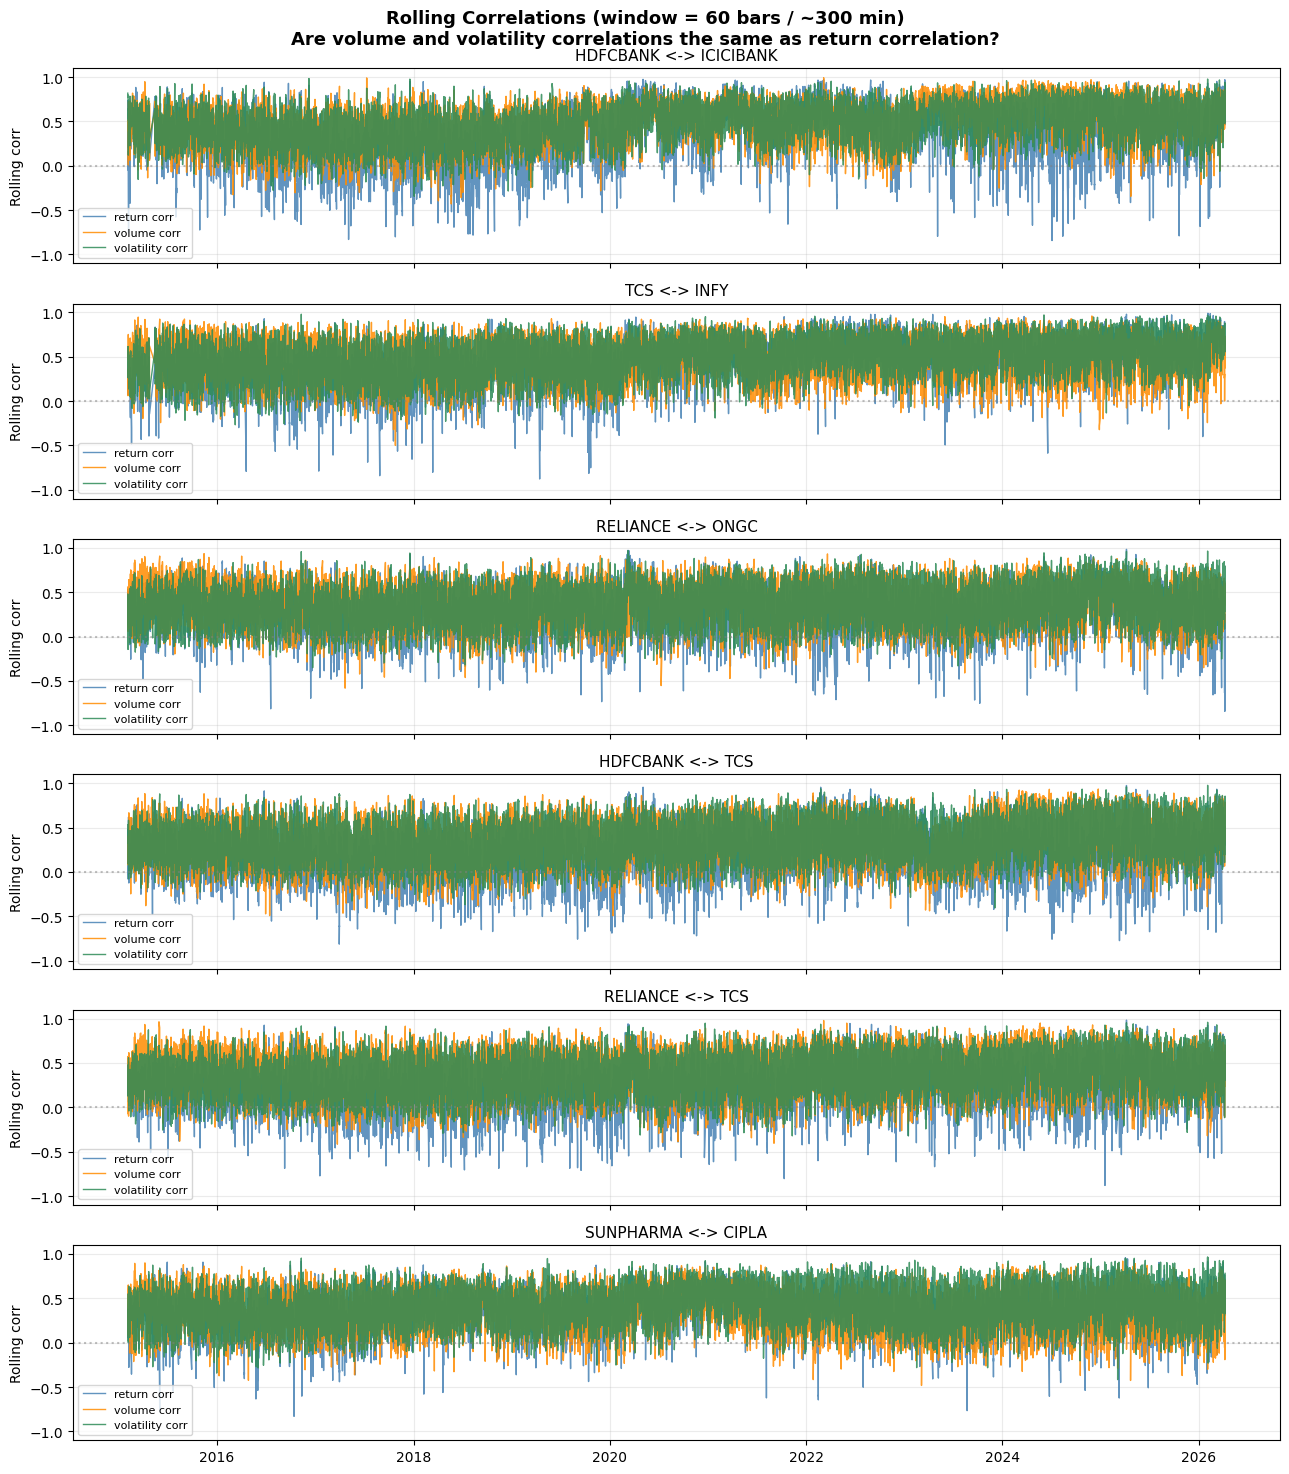

Saved: c:\Users\HP\Documents\InterStockRelation_Paper\InterStockRelation\outputs\plots\volume_signal_check.png


In [5]:
# Cell 5 - Visualize: 6 pairs x 1 plot each, three streams overlaid

n_pairs = len(pair_streams)
fig, axes = plt.subplots(n_pairs, 1, figsize=(13, 2.5 * n_pairs),
                         sharex=True)
if n_pairs == 1:
    axes = [axes]
fig.suptitle(f'Rolling Correlations (window = {ROLL_WINDOW} bars / ~{ROLL_WINDOW*5} min)\n'
             f'Are volume and volatility correlations the same as return correlation?',
             fontsize=13, fontweight='bold')

for ax, ((a, b), df) in zip(axes, pair_streams.items()):
    # Downsample for plot speed if needed
    plot_df = df.iloc[::10] if len(df) > 5000 else df
    ax.plot(plot_df.index, plot_df['return_corr'],     label='return corr',     color='steelblue',  alpha=0.85, lw=1)
    ax.plot(plot_df.index, plot_df['volume_corr'],     label='volume corr',     color='darkorange', alpha=0.85, lw=1)
    ax.plot(plot_df.index, plot_df['volatility_corr'], label='volatility corr', color='seagreen',   alpha=0.85, lw=1)
    ax.axhline(0, color='grey', linestyle=':', alpha=0.5)
    ax.set_title(f'{a} <-> {b}', fontsize=11)
    ax.set_ylabel('Rolling corr')
    ax.set_ylim(-1.1, 1.1)
    ax.legend(fontsize=8, loc='lower left')
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'volume_signal_check.png'),
            dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved: {os.path.join(PLOTS_DIR, "volume_signal_check.png")}')


In [6]:
# Cell 6 - Verdict & Recommendation

n_independent  = (redund_df['verdict'] == 'INDEPENDENT').sum()
n_partial      = (redund_df['verdict'] == 'partial overlap').sum()
n_redundant    = (redund_df['verdict'] == 'REDUNDANT').sum()

print('VERDICT')
print('='*60)
print(f'  Independent streams : {n_independent}/{len(redund_df)} pairs')
print(f'  Partial overlap     : {n_partial}/{len(redund_df)} pairs')
print(f'  Redundant           : {n_redundant}/{len(redund_df)} pairs')
print()

avg_ret_vol = redund_df['ret_vol'].mean()
avg_ret_rng = redund_df['ret_rng'].mean()
avg_vol_rng = redund_df['vol_rng'].mean()
print(f'Average cross-stream correlations:')
print(f'  return  vs volume     : {avg_ret_vol:+.4f}')
print(f'  return  vs volatility : {avg_ret_rng:+.4f}')
print(f'  volume  vs volatility : {avg_vol_rng:+.4f}')
print()

if n_independent + n_partial >= len(redund_df) / 2:
    print('RECOMMENDATION: BUILD TRIAL 7.')
    print('  Volume and/or volatility carry information distinct from return correlation.')
    print('  A multi-channel pair-pixel architecture should be able to exploit this.')
elif n_redundant >= len(redund_df) - 1:
    print('RECOMMENDATION: SKIP volume/volatility streams.')
    print('  All three correlation types move together. Adding them as channels would')
    print('  just give the model duplicated information. Look elsewhere (Tier 2 macro).')
else:
    print('RECOMMENDATION: BUILD A TARGETED VERSION OF TRIAL 7.')
    print('  Mixed signal across pairs. Include volume/volatility streams but use')
    print('  attention or gating to let the model decide when to rely on each.')


VERDICT
  Independent streams : 6/6 pairs
  Partial overlap     : 0/6 pairs
  Redundant           : 0/6 pairs

Average cross-stream correlations:
  return  vs volume     : +0.1785
  return  vs volatility : +0.2512
  volume  vs volatility : +0.4935

RECOMMENDATION: BUILD TRIAL 7.
  Volume and/or volatility carry information distinct from return correlation.
  A multi-channel pair-pixel architecture should be able to exploit this.
